<a href="https://colab.research.google.com/github/arielsharonferdinandus/Transboundary-Haze-Forecasting/blob/data-setup-and-load/Transboundary_Haze_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transboundary Haze Forecasting: Predicting PM2.5 Spikes in Singapore
**Theme:** Energy & Environment (Air Quality) | **Type:** Time-Series Forecasting

## Part 1: Problem Formulation, Data Audit & Preprocessing (Phases 1-2)

**Stakeholder:** National Environment Agency (NEA) Singapore / Director of Public Health.

**Predictive question:** Can historical PM2.5 and meteorological sensor data across four Singapore sites forecast PM2.5 spikes 24-48 hours ahead during Indonesian land and forest fire (karhutla) haze events?

**Target:** `pm25` (ug/m3), hourly, per station and city-wide mean.

**Unit of analysis:** hourly timestamp x sensor location (Marina Bay, Marine Terrace, Alexandra Canal, Waterscape at Cavenagh).

> Scope note: the model *predicts haze arrival from observed air-quality signals*. It does not simulate fire ignition and makes no causal claims about fires.

## 0. Setup

In [ ]:
!pip -q install pandas numpy matplotlib seaborn
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4.5)

## 1. Load the data
Put the 4 CSVs in a `data/` folder. On Colab, run the cell below: if the files are not found it opens an upload dialog and saves them into `data/`.

In [ ]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

STATIONS = {
    "6546759": "Marina Bay",
    "6301631": "Marine Terrace",
    "6536821": "Alexandra Canal",
    "6551473": "Waterscape at Cavenagh",
}

def find_files():
    return sorted(glob.glob(os.path.join(DATA_DIR, "openaq_location_*_measurments.csv")) +
                  glob.glob(os.path.join(DATA_DIR, "openaq_location_*_measurements.csv")))

if len(find_files()) < 4:
    try:
        from google.colab import files
        print("Upload the 4 openaq_location_*.csv files")
        up = files.upload()
        for name, content in up.items():
            with open(os.path.join(DATA_DIR, name), "wb") as f:
                f.write(content)
    except ImportError:
        print("Not on Colab: copy the CSVs into ./data manually.")

files_found = find_files()
print(len(files_found), "files found:")
for f in files_found: print("  ", f)
assert len(files_found) == 4, "Expected 4 station files"

4 files found:
   data/openaq_location_6301631_measurments.csv
   data/openaq_location_6536821_measurments.csv
   data/openaq_location_6546759_measurments.csv
   data/openaq_location_6551473_measurments.csv


In [ ]:
raw = {}
for f in files_found:
    loc_id = [k for k in STATIONS if k in f][0]
    df = pd.read_csv(f)
    df["station"] = STATIONS[loc_id]
    raw[STATIONS[loc_id]] = df
    print(f"{STATIONS[loc_id]:25s} shape={df.shape}")

# Inspect structure of the first file
first = next(iter(raw.values()))
print("\nColumns:", list(first.columns))
first.head()

Marine Terrace            shape=(5000, 16)
Alexandra Canal           shape=(3770, 16)
Marina Bay                shape=(3075, 16)
Waterscape at Cavenagh    shape=(455, 16)

Columns: ['location_id', 'location_name', 'parameter', 'value', 'unit', 'datetimeUtc', 'datetimeLocal', 'timezone', 'latitude', 'longitude', 'country_iso', 'isMobile', 'isMonitor', 'owner_name', 'provider', 'station']


,location_id,location_name,parameter,value,unit,datetimeUtc,datetimeLocal,timezone,latitude,longitude,country_iso,isMobile,isMonitor,owner_name,provider,station
0,6301631,Marine Terrace,pm1,7.0,µg/m³,2026-04-09T11:00:00Z,2026-04-09T19:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,Marine Terrace
1,6301631,Marine Terrace,pm1,5.6,µg/m³,2026-04-09T12:00:00Z,2026-04-09T20:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,Marine Terrace
2,6301631,Marine Terrace,pm1,8.7,µg/m³,2026-04-09T13:00:00Z,2026-04-09T21:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,Marine Terrace
3,6301631,Marine Terrace,pm1,8.5,µg/m³,2026-04-09T14:00:00Z,2026-04-09T22:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,Marine Terrace
4,6301631,Marine Terrace,pm1,15.6,µg/m³,2026-04-09T15:00:00Z,2026-04-09T23:00:00+08:00,Asia/Singapore,1.296704,103.918619,NaN,NaN,NaN,Matt Ranostay,AirGradient,Marine Terrace


In [ ]:
# Combine into one long dataframe and inspect parameters
long_raw = pd.concat(raw.values(), ignore_index=True)
print(long_raw["parameter"].value_counts(), "\n")
print("Units per parameter:")
print(long_raw.groupby("parameter")["unit"].unique(), "\n")
print("Rows per station x parameter:")
long_raw.groupby(["station", "parameter"]).size().unstack(fill_value=0)

parameter
pm1                 2460
pm25                2460
relativehumidity    2460
temperature         2460
um003               2460
Name: count, dtype: int64 

Units per parameter:
parameter
pm1                         [µg/m³]
pm25                        [µg/m³]
relativehumidity                [%]
temperature                     [c]
um003               [particles/cm³]
Name: unit, dtype: object 

Rows per station x parameter:


parameter,pm1,pm25,relativehumidity,temperature,um003
station,,,,,
Alexandra Canal,754,754,754,754,754
Marina Bay,615,615,615,615,615
Marine Terrace,1000,1000,1000,1000,1000
Waterscape at Cavenagh,91,91,91,91,91


## 2. Data audit (raw)
Checks: missing values, duplicates, invalid sensor values (negative PM2.5, humidity outside 0-100%, exact-zero PM readings), time coverage and sampling interval.

In [ ]:
# Parse timestamps (datetimeLocal; drop the +08:00 offset so everything is Singapore wall-clock time)
ts = pd.to_datetime(long_raw["datetimeLocal"], errors="coerce")
if getattr(ts.dt, "tz", None) is not None:
    ts = ts.dt.tz_localize(None)
long_raw["time"] = ts
long_raw["value"] = pd.to_numeric(long_raw["value"], errors="coerce")

audit = pd.DataFrame({
    "null_time": [long_raw["time"].isna().sum()],
    "null_value": [long_raw["value"].isna().sum()],
    "duplicate_rows(station,time,param)": [long_raw.duplicated(["station", "time", "parameter"]).sum()],
})
display(audit)

print("Time coverage per station (all parameters):")
display(long_raw.groupby("station")["time"].agg(["min", "max", "count"]))

,null_time,null_value,"duplicate_rows(station,time,param)"
0,0,0,0


Time coverage per station (all parameters):


,min,max,count
station,,,
Alexandra Canal,2026-09-12 23:00:00,2026-10-14 08:00:00,3770
Marina Bay,2026-09-18 18:00:00,2026-10-14 08:00:00,3075
Marine Terrace,2026-04-09 19:00:00,2026-06-07 14:00:00,5000
Waterscape at Cavenagh,2026-10-10 14:00:00,2026-10-14 08:00:00,455


In [ ]:
# Value ranges and invalid values per parameter
display(long_raw.groupby("parameter")["value"].describe().round(2))

P = long_raw.parameter
invalid = {
    "negative pm25":                           ((P == "pm25") & (long_raw.value < 0)).sum(),
    "negative pm1":                            ((P == "pm1") & (long_raw.value < 0)).sum(),
    "exact zero pm25 (sensor dropout/warm-up)": ((P == "pm25") & (long_raw.value == 0)).sum(),
    "exact zero pm1":                          ((P == "pm1") & (long_raw.value == 0)).sum(),
    "humidity <0 or >100":                     ((P == "relativehumidity") & ((long_raw.value < 0) | (long_raw.value > 100))).sum(),
    "temperature <15 or >45 C (implausible)":  ((P == "temperature") & ((long_raw.value < 15) | (long_raw.value > 45))).sum(),
    "negative um003":                          ((P == "um003") & (long_raw.value < 0)).sum(),
    "pm25 < pm1 (physically inconsistent)":    0,
}
# pm25 < pm1 check on matching timestamps
pv = long_raw[long_raw.parameter.isin(["pm1", "pm25"])].pivot_table(index=["station", "time"], columns="parameter", values="value")
invalid["pm25 < pm1 (physically inconsistent)"] = int((pv["pm25"] < pv["pm1"]).sum())
print("Invalid / suspicious counts:")
for k, v in invalid.items(): print(f"  {k:45s} {v}")

,count,mean,std,min,25%,50%,75%,max
parameter,,,,,,,,
pm1,2460.0,30.33,23.59,0.0,8.50,26.65,45.70,171.8
pm25,2460.0,55.54,46.25,0.0,18.50,42.80,85.85,292.6
relativehumidity,2460.0,57.38,4.93,41.0,55.00,57.00,61.00,82.0
temperature,2460.0,29.83,1.55,24.3,28.80,30.10,30.70,35.0
um003,2460.0,2224.30,1792.42,52.0,679.25,1661.50,3488.00,12460.0


Invalid / suspicious counts:
  negative pm25                                 0
  negative pm1                                  0
  exact zero pm25 (sensor dropout/warm-up)      17
  exact zero pm1                                47
  humidity <0 or >100                           0
  temperature <15 or >45 C (implausible)        0
  negative um003                                0
  pm25 < pm1 (physically inconsistent)          0


In [ ]:
# Sampling interval (irregular timestamps?) for pm25
pm = long_raw[long_raw.parameter == "pm25"].sort_values(["station", "time"])
pm["gap"] = pm.groupby("station")["time"].diff()
print("Sampling intervals between consecutive pm25 readings (all stations):")
display(pm["gap"].value_counts().sort_index().to_frame("count"))
print("Gaps longer than 3 hours:")
display(pm.loc[pm["gap"] > pd.Timedelta("3h"), ["station", "time", "gap"]])

Sampling intervals between consecutive pm25 readings (all stations):


,count
gap,
0 days 01:00:00,2451
0 days 02:00:00,3
0 days 03:00:00,1
17 days 00:00:00,1


Gaps longer than 3 hours:


,station,time,gap
1456,Marine Terrace,2026-05-15 22:00:00,17 days


## 3. Cleaning & hourly resampling
Steps:
1. Drop rows with unparseable time or value.
2. Set invalid values to NaN: negative PM, **exact-zero PM1/PM2.5** (sensor start-up / dropout readings, not real air), humidity outside 0-100, implausible temperature.
3. Average duplicates and resample every series to a regular **hourly** grid.

In [ ]:
clean = long_raw.dropna(subset=["time", "value"]).copy()

bad = (
    (clean.parameter.isin(["pm1", "pm25", "um003"]) & (clean.value < 0)) |
    (clean.parameter.isin(["pm1", "pm25"]) & (clean.value == 0)) |
    ((clean.parameter == "relativehumidity") & ~clean.value.between(0, 100)) |
    ((clean.parameter == "temperature") & ~clean.value.between(15, 45))
)
print("Rows set to NaN as invalid:", int(bad.sum()))
clean.loc[bad, "value"] = np.nan

clean["hour"] = clean["time"].dt.floor("h")
hourly = (clean.groupby(["station", "parameter", "hour"])["value"].mean()
               .reset_index())
print("Hourly records:", len(hourly))
hourly.head()

Rows set to NaN as invalid: 64
Hourly records: 12300


,station,parameter,hour,value
0,Alexandra Canal,pm1,2026-09-12 23:00:00,NaN
1,Alexandra Canal,pm1,2026-09-13 00:00:00,28.4
2,Alexandra Canal,pm1,2026-09-13 01:00:00,29.6
3,Alexandra Canal,pm1,2026-09-13 02:00:00,30.3
4,Alexandra Canal,pm1,2026-09-13 03:00:00,30.8


## 4. Wide-format merge across the 4 stations
Columns are named `{parameter}__{station}`, indexed by a complete hourly `DatetimeIndex`.

In [ ]:
PARAMS = ["pm1", "pm25", "relativehumidity", "temperature", "um003"]
wide = hourly.pivot_table(index="hour", columns=["parameter", "station"], values="value")
wide.columns = [f"{p}__{s.replace(' ', '_')}" for p, s in wide.columns]

full_idx = pd.date_range(wide.index.min(), wide.index.max(), freq="h")
wide = wide.reindex(full_idx)
wide.index.name = "datetime"
print("Merged grid:", wide.shape, "|", wide.index.min(), "->", wide.index.max())
wide.iloc[:3, :6]

Merged grid: (4502, 20) | 2026-04-09 19:00:00 -> 2026-10-14 08:00:00


,pm1__Alexandra_Canal,pm1__Marina_Bay,pm1__Marine_Terrace,pm1__Waterscape_at_Cavenagh,pm25__Alexandra_Canal,pm25__Marina_Bay
datetime,,,,,,
2026-04-09 19:00:00,NaN,NaN,7.0,NaN,NaN,NaN
2026-04-09 20:00:00,NaN,NaN,5.6,NaN,NaN,NaN
2026-04-09 21:00:00,NaN,NaN,8.7,NaN,NaN,NaN


### 4a. Coverage & overlap between stations
**This step matters:** a city-wide mean and cross-station features only make sense where stations are observed at the same time.

,first,last,span_hours,observed_hours,missing_inside_span
station,,,,,
Alexandra_Canal,2026-09-13 00:00:00,2026-10-14 08:00:00,753,753,0
Marina_Bay,2026-09-18 18:00:00,2026-10-14 08:00:00,615,615,0
Marine_Terrace,2026-04-09 19:00:00,2026-06-07 14:00:00,1412,984,428
Waterscape_at_Cavenagh,2026-10-10 14:00:00,2026-10-14 08:00:00,91,91,0


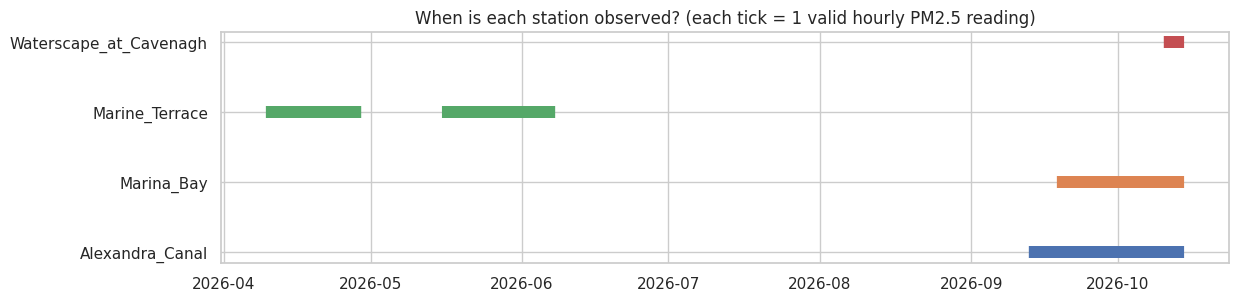

In [ ]:
pm_all = [c for c in wide.columns if c.startswith("pm25__")]
rows = []
for c in pm_all:
    s = wide[c]; first, last = s.first_valid_index(), s.last_valid_index()
    inside = s.loc[first:last]
    rows.append({"station": c.replace("pm25__", ""), "first": first, "last": last,
                 "span_hours": len(inside), "observed_hours": int(inside.notna().sum()),
                 "missing_inside_span": int(inside.isna().sum())})
coverage = pd.DataFrame(rows).set_index("station")
display(coverage)

fig, ax = plt.subplots(figsize=(13, 3))
for i, c in enumerate(pm_all):
    idx = wide[c].dropna().index
    ax.scatter(idx, [i] * len(idx), marker="|", s=80)
ax.set_yticks(range(len(pm_all))); ax.set_yticklabels([c.replace("pm25__", "") for c in pm_all])
ax.set_title("When is each station observed? (each tick = 1 valid hourly PM2.5 reading)")
plt.show()

In [ ]:
# ---- CONFIG: stations used to build the city-wide mean and the modelling window ----
# Default = stations whose observation periods overlap for a long continuous stretch.
# If you re-export Marine Terrace for Jun-Oct, add "Marine_Terrace" here and re-run.
CORE_STATIONS = ["Alexandra_Canal", "Marina_Bay"]

core_pm = [f"pm25__{s}" for s in CORE_STATIONS]
MODEL_START = max(wide[c].first_valid_index() for c in core_pm)
MODEL_END   = min(wide[c].last_valid_index()  for c in core_pm)
n_hours = int((MODEL_END - MODEL_START) / pd.Timedelta("1h")) + 1
print(f"Core stations : {CORE_STATIONS}")
print(f"Modelling window: {MODEL_START}  ->  {MODEL_END}  ({n_hours} hours = {n_hours/24:.1f} days)")

print("\nValid PM2.5 hours inside the modelling window, per station:")
inwin = wide.loc[MODEL_START:MODEL_END, pm_all].notna().sum()
display(inwin.rename(lambda c: c.replace("pm25__", "")).to_frame("hours_in_window"))

Core stations : ['Alexandra_Canal', 'Marina_Bay']
Modelling window: 2026-09-18 18:00:00  ->  2026-10-14 08:00:00  (615 hours = 25.6 days)

Valid PM2.5 hours inside the modelling window, per station:


,hours_in_window
Alexandra_Canal,615
Marina_Bay,615
Marine_Terrace,0
Waterscape_at_Cavenagh,91


**What this means for the project** (based on the provided exports; the cell above prints the exact numbers):
- Marine Terrace and Waterscape at Cavenagh do not cover the same period as Alexandra Canal and Marina Bay, so they cannot be part of a city-wide mean over the window.
- The modelling window is short (a few weeks of hourly data). Forecast evaluation will rest on only a few days of test data, and month / season features carry no information within one season.
- Low-cost optical (AirGradient) sensors can read higher than regulatory monitors in haze. Treat absolute levels with caution; relative spikes and timing are the strength of this data.
- NEA's *1-hour* PM2.5 bands (Normal <=55, Elevated 56-150, High 151-250, Very High >250 ug/m3) are used below as a reference scale. They are not themselves health advisories (those use the 24-hour PSI).

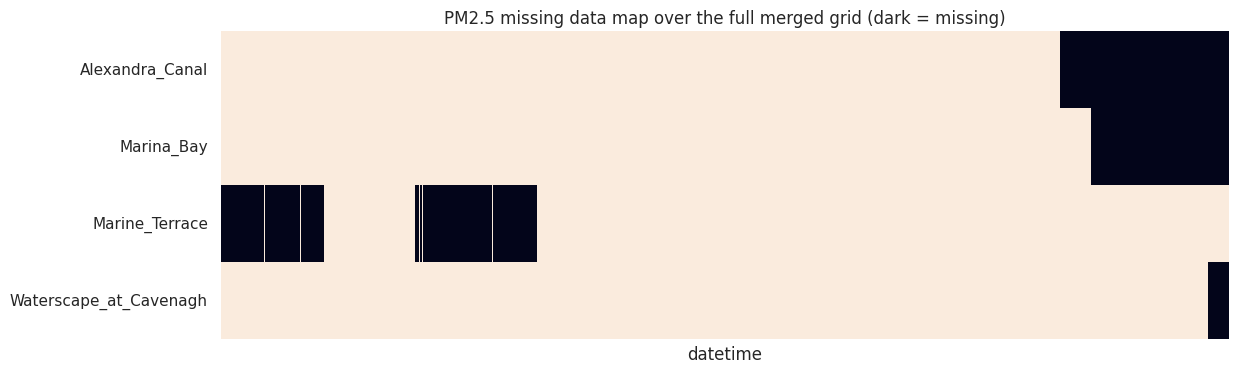

In [ ]:
# Missingness on the full grid (shows the non-overlap clearly)
plt.figure(figsize=(13, 4))
sns.heatmap(wide[pm_all].isna().T, cbar=False, xticklabels=False,
            yticklabels=[c.replace("pm25__", "") for c in pm_all])
plt.title("PM2.5 missing data map over the full merged grid (dark = missing)")
plt.show()

## 5. Missing-value handling (no leakage)
- **Forward-fill, at most 6 hours** per gap. It only uses past values, so it cannot leak future information into training or test periods.
- Values are never filled **before a series starts or after it ends** (so a station is not extended beyond its real observation period).
- Longer gaps stay NaN and are dropped later (after lag creation) rather than inventing data.
- No mean / median imputation. Any scaling later is fit on the **train split only**.

In [ ]:
filled = wide.ffill(limit=6)
for c in wide.columns:                       # do not extend a series past its last real reading
    last = wide[c].last_valid_index()
    if last is not None:
        filled.loc[filled.index > last, c] = np.nan

print(f"NaN cells (full grid): {int(wide.isna().sum().sum())} -> {int(filled.isna().sum().sum())}")
print("Hours filled by forward-fill, per PM2.5 column:")
display((filled[pm_all].notna().sum() - wide[pm_all].notna().sum()).to_frame("hours_filled"))

NaN cells (full grid): 77804 -> 77688
Hours filled by forward-fill, per PM2.5 column:


,hours_filled
pm25__Alexandra_Canal,0
pm25__Marina_Bay,0
pm25__Marine_Terrace,27
pm25__Waterscape_at_Cavenagh,0


## 6. Build the modelling dataframe
Slice to the overlap window, keep only columns that actually have data in it, and compute the **city-wide mean over the core stations** (spatial aggregation).

In [ ]:
model = filled.loc[MODEL_START:MODEL_END].copy()
keep = [c for c in model.columns if model[c].notna().any()]
dropped = [c for c in model.columns if c not in keep]
model = model[keep]
print("Columns without any data in the window (excluded):", sorted({c.split('__')[1] for c in dropped}))

for p in PARAMS:
    cols = [f"{p}__{s}" for s in CORE_STATIONS if f"{p}__{s}" in model.columns]
    model[f"{p}_citymean"] = model[cols].mean(axis=1, skipna=True)
model["n_core_stations_pm25"] = model[core_pm].notna().sum(axis=1)

print("Model frame:", model.shape)
print("NaN in pm25_citymean:", int(model["pm25_citymean"].isna().sum()))
print("Hours with fewer than all core stations reporting:", int((model["n_core_stations_pm25"] < len(CORE_STATIONS)).sum()))
model[[c for c in model.columns if c.startswith("pm25")]].describe().round(1)

Columns without any data in the window (excluded): ['Marine_Terrace']
Model frame: (615, 21)
NaN in pm25_citymean: 0
Hours with fewer than all core stations reporting: 0


,pm25__Alexandra_Canal,pm25__Marina_Bay,pm25__Waterscape_at_Cavenagh,pm25_citymean
count,615.0,615.0,91.0,615.0
mean,87.0,76.2,109.3,81.6
std,45.2,38.0,22.2,41.3
min,4.4,6.4,55.0,5.4
25%,46.8,43.8,94.4,45.2
50%,76.3,65.4,109.4,70.9
75%,123.8,105.2,129.2,113.7
max,204.1,194.2,153.8,199.1


## 7. Exploratory data analysis (modelling window)

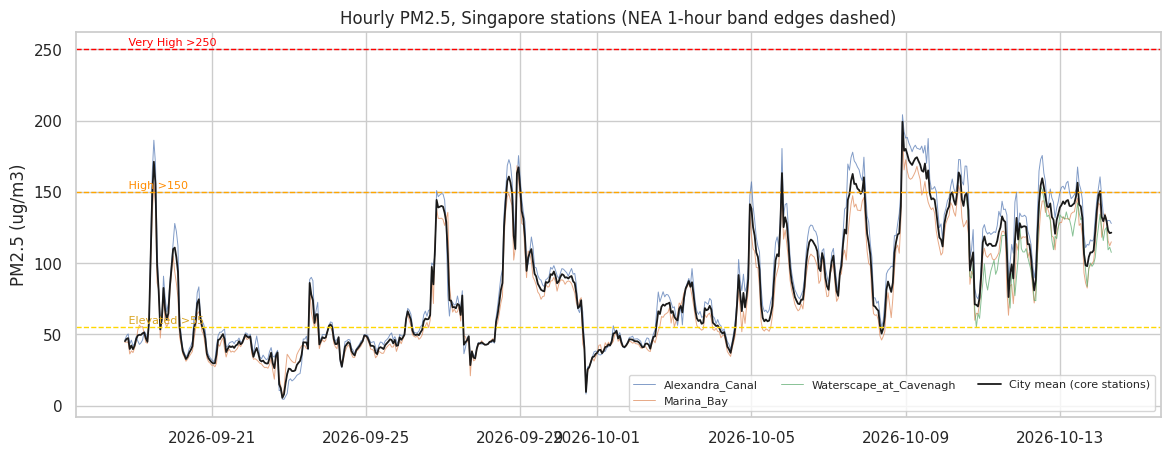

In [ ]:
BANDS = [55, 150, 250]
pm_cols_model = [c for c in model.columns if c.startswith("pm25__")]

fig, ax = plt.subplots(figsize=(14, 5))
for c in pm_cols_model:
    ax.plot(model.index, model[c], lw=0.7, alpha=0.7, label=c.replace("pm25__", ""))
ax.plot(model.index, model["pm25_citymean"], color="k", lw=1.3, label="City mean (core stations)")
for b, col in zip(BANDS, ["gold", "orange", "red"]):
    ax.axhline(b, color=col, ls="--", lw=1)
ax.text(model.index[0], 56, " Elevated >55", color="goldenrod", fontsize=8, va="bottom")
ax.text(model.index[0], 151, " High >150", color="darkorange", fontsize=8, va="bottom")
ax.text(model.index[0], 251, " Very High >250", color="red", fontsize=8, va="bottom")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.set_title("Hourly PM2.5, Singapore stations (NEA 1-hour band edges dashed)")
ax.legend(ncol=3, fontsize=8); plt.show()

In [ ]:
# Time spent in each NEA 1-hour PM2.5 band
labels = ["Normal (<=55)", "Elevated (56-150)", "High (151-250)", "Very High (>250)"]
def band_share(s):
    return pd.cut(s.dropna(), [-np.inf, 55, 150, 250, np.inf], labels=labels).value_counts(normalize=True).reindex(labels).mul(100).round(1)
tbl = pd.DataFrame({"City mean": band_share(model["pm25_citymean"]),
                    **{c.replace("pm25__", ""): band_share(model[c]) for c in pm_cols_model}})
print("% of hours in each band:"); display(tbl)

% of hours in each band:


,City mean,Alexandra_Canal,Marina_Bay,Waterscape_at_Cavenagh
Normal (<=55),36.9,35.0,40.8,1.1
Elevated (56-150),56.4,52.5,56.3,96.7
High (151-250),6.7,12.5,2.9,2.2
Very High (>250),0.0,0.0,0.0,0.0


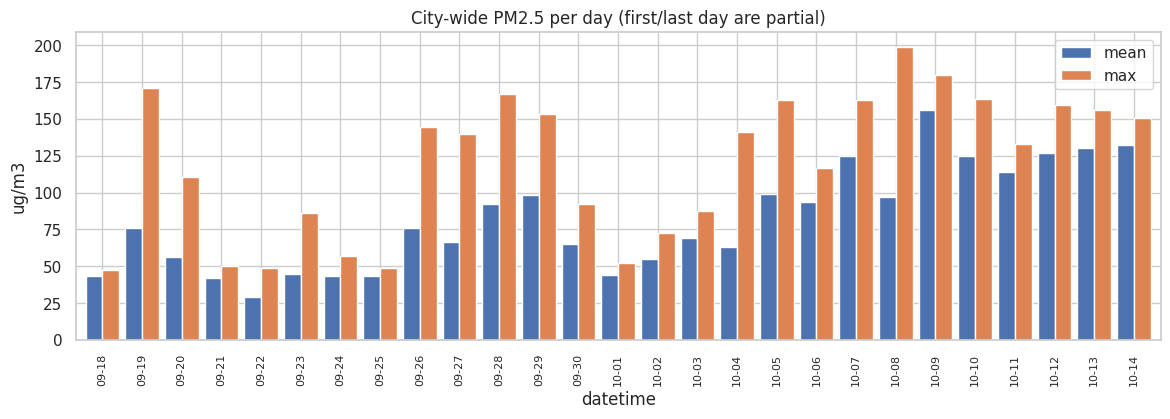

In [ ]:
daily = model["pm25_citymean"].resample("D").agg(["mean", "max", "count"])
ax = daily[["mean", "max"]].plot(kind="bar", figsize=(14, 4), width=0.85)
ax.set_xticklabels([d.strftime("%m-%d") for d in daily.index], rotation=90, fontsize=8)
ax.set_title("City-wide PM2.5 per day (first/last day are partial)"); ax.set_ylabel("ug/m3"); plt.show()

In [ ]:
# Spike definition for EDA: city-mean above its 95th percentile (illustrative; labels in Phase 3 will use TRAIN data only)
thr = model["pm25_citymean"].quantile(0.95)
spike = model["pm25_citymean"] > thr
print(f"95th percentile of city-mean PM2.5 = {thr:.1f} ug/m3  ->  {int(spike.sum())} spike hours of {len(model)}")

# Do the core stations rise together?
own_thr = model[core_pm].quantile(0.95)
above = model[core_pm] > own_thr
any_hr, all_hr = above.any(axis=1), above.all(axis=1)
print(f"Hours where >=1 core station is in its own top 5%: {int(any_hr.sum())}")
print(f"  ...of which ALL core stations are in their top 5% together: {int(all_hr.sum())} ({all_hr.sum()/max(any_hr.sum(),1)*100:.0f}%)")

ep = (spike != spike.shift()).cumsum()
episodes = (model[spike].groupby(ep[spike])["pm25_citymean"]
            .agg(start=lambda s: s.index.min(), end=lambda s: s.index.max(), peak="max"))
episodes["hours"] = (episodes["end"] - episodes["start"]).dt.total_seconds() / 3600 + 1
print(f"\n{len(episodes)} spike episodes, longest / highest first:")
display(episodes.sort_values(["peak"], ascending=False).head(10).reset_index(drop=True))

95th percentile of city-mean PM2.5 = 155.9 ug/m3  ->  31 spike hours of 615
Hours where >=1 core station is in its own top 5%: 38
  ...of which ALL core stations are in their top 5% together: 24 (63%)

10 spike episodes, longest / highest first:


,start,end,peak,hours
0,2026-10-08 22:00:00,2026-10-09 14:00:00,199.15,17.0
1,2026-09-19 12:00:00,2026-09-19 12:00:00,171.10,1.0
2,2026-09-28 22:00:00,2026-09-28 23:00:00,167.20,2.0
3,2026-10-10 09:00:00,2026-10-10 10:00:00,163.60,2.0
4,2026-10-05 19:00:00,2026-10-05 19:00:00,163.15,1.0
5,2026-10-07 14:00:00,2026-10-07 15:00:00,162.55,2.0
6,2026-09-28 16:00:00,2026-09-28 18:00:00,160.70,3.0
7,2026-10-07 22:00:00,2026-10-07 22:00:00,160.20,1.0
8,2026-10-12 13:00:00,2026-10-12 13:00:00,159.50,1.0
9,2026-10-13 11:00:00,2026-10-13 11:00:00,156.40,1.0


Overlapping hours per pair:


,Alexandra_Canal,Marina_Bay,Waterscape_at_Cavenagh
Alexandra_Canal,615,615,91
Marina_Bay,615,615,91
Waterscape_at_Cavenagh,91,91,91


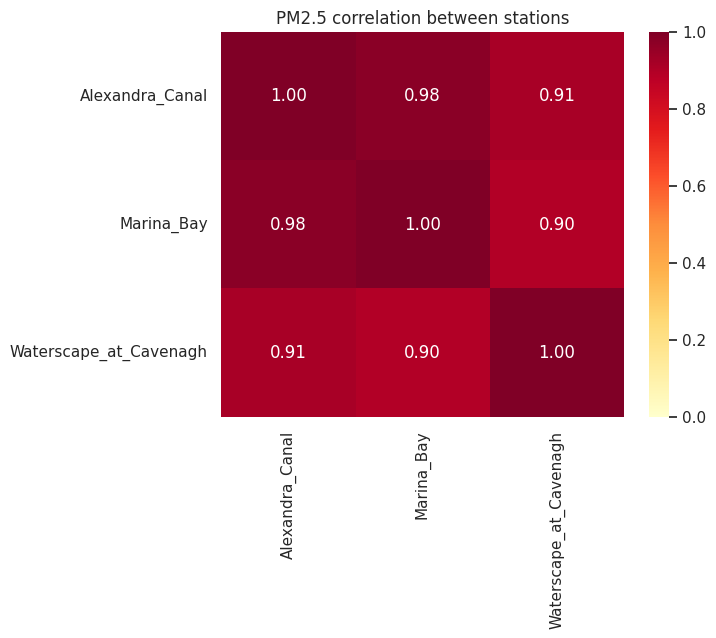

In [ ]:
# Cross-station correlation in the window (pairwise; Cavenagh has few overlapping hours)
corr = model[pm_cols_model].rename(columns=lambda c: c.replace("pm25__", "")).corr()
nobs = model[pm_cols_model].rename(columns=lambda c: c.replace("pm25__", "")).notna().astype(int)
print("Overlapping hours per pair:"); display(nobs.T.dot(nobs))
plt.figure(figsize=(6.5, 5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1)
plt.title("PM2.5 correlation between stations"); plt.show()

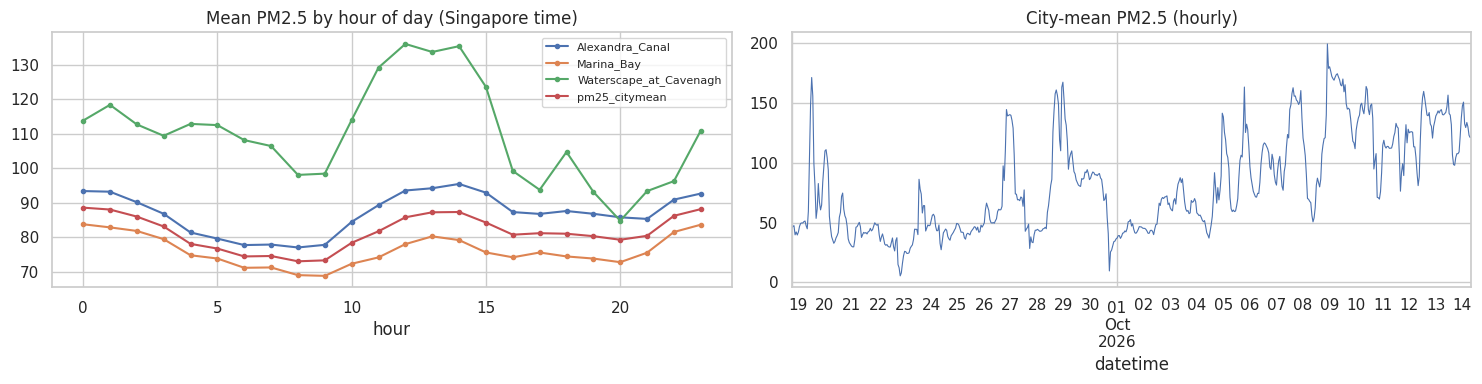

In [ ]:
# Diurnal pattern + daily profile
tmp = model.copy(); tmp["hour"] = tmp.index.hour
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for c in pm_cols_model + ["pm25_citymean"]:
    tmp.groupby("hour")[c].mean().plot(ax=axes[0], marker="o", ms=3, label=c.replace("pm25__", ""))
axes[0].set_title("Mean PM2.5 by hour of day (Singapore time)"); axes[0].legend(fontsize=8)
tmp["pm25_citymean"].plot(ax=axes[1], lw=0.8); axes[1].set_title("City-mean PM2.5 (hourly)")
plt.tight_layout(); plt.show()

In [ ]:
# Persistence preview: how strongly is PM2.5 related to its own past? (motivates Phase 3 lag features)
s = model["pm25_citymean"]
acf = pd.Series({f"lag {k}h": s.autocorr(k) for k in [1, 3, 6, 12, 24, 48]}).round(3)
print("Autocorrelation of city-mean PM2.5:"); display(acf.to_frame("autocorr"))

Autocorrelation of city-mean PM2.5:


,autocorr
lag 1h,0.966
lag 3h,0.865
lag 6h,0.725
lag 12h,0.569
lag 24h,0.490
lag 48h,0.461


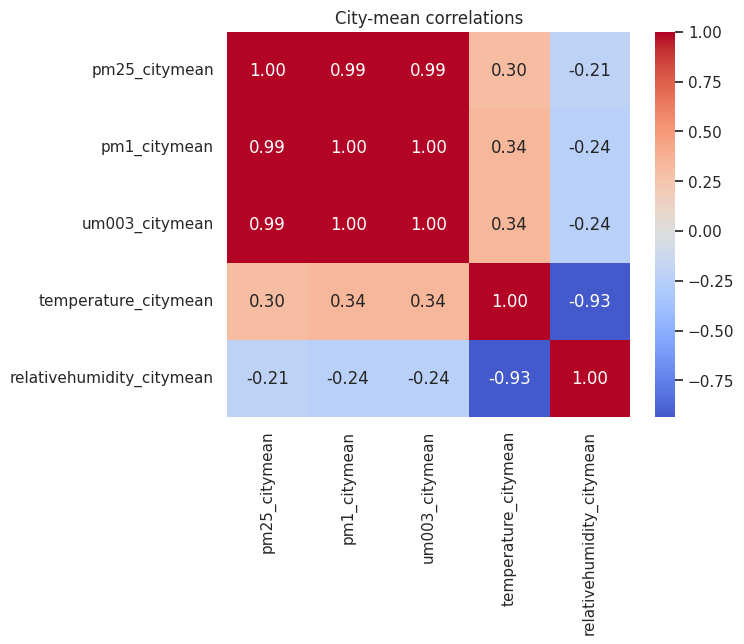

In [ ]:
# PM vs meteorology (core-station city means)
core = [c for c in ["pm25_citymean", "pm1_citymean", "um003_citymean",
                    "temperature_citymean", "relativehumidity_citymean"] if c in model.columns]
plt.figure(figsize=(6.5, 5))
sns.heatmap(model[core].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("City-mean correlations"); plt.show()

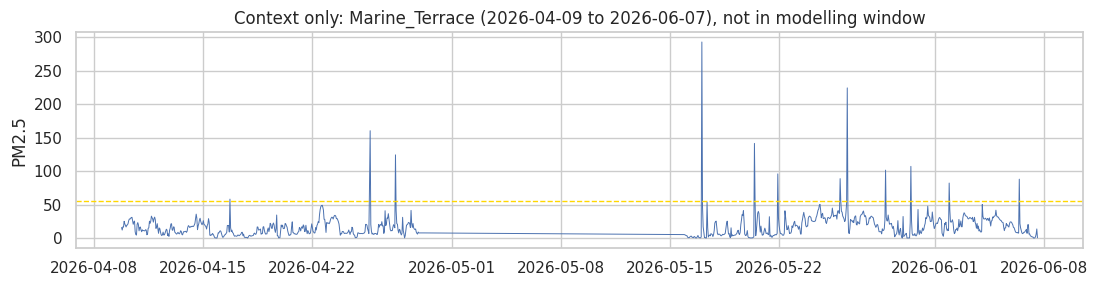

In [ ]:
# Context only: stations outside the overlap window (not used for modelling)
ctx = [c for c in dropped if c.startswith("pm25__")]
for c in ctx:
    s = filled[c].dropna()
    fig, ax = plt.subplots(figsize=(13, 2.8)); ax.plot(s.index, s.values, lw=0.7)
    ax.axhline(55, color="gold", ls="--", lw=1)
    ax.set_title(f"Context only: {c.replace('pm25__', '')} ({s.index.min():%Y-%m-%d} to {s.index.max():%Y-%m-%d}), not in modelling window")
    ax.set_ylabel("PM2.5"); plt.show()

## 8. Save cleaned datasets for the next parts

In [ ]:
model.to_csv("clean_hourly_model.csv")           # used for Phase 3+
filled.to_csv("clean_hourly_wide_all.csv")       # full grid, all stations (reference)
print("Saved clean_hourly_model.csv    ", model.shape, f"{model.index.min()} -> {model.index.max()}")
print("Saved clean_hourly_wide_all.csv ", filled.shape)
try:
    from google.colab import files
    files.download("clean_hourly_model.csv"); files.download("clean_hourly_wide_all.csv")
except Exception:
    pass

Saved clean_hourly_model.csv     (615, 21) 2026-09-18 18:00:00 -> 2026-10-14 08:00:00
Saved clean_hourly_wide_all.csv  (4502, 20)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ---- Part 1 summary (auto-generated) ----
print("=== PART 1 SUMMARY ===")
print(f"Raw files: {len(files_found)} | raw rows: {len(long_raw)} | invalid/zero values set to NaN: {int(bad.sum())}")
print(f"Full merged grid: {wide.shape[0]} hourly timestamps ({wide.index.min():%Y-%m-%d} to {wide.index.max():%Y-%m-%d})")
print(f"Core stations: {CORE_STATIONS}")
print(f"Modelling window: {MODEL_START} -> {MODEL_END} = {len(model)} hours ({len(model)/24:.1f} days)")
print(f"City-mean PM2.5: mean {model.pm25_citymean.mean():.1f}, max {model.pm25_citymean.max():.1f} ug/m3")
print(f"Share of hours above NEA 'Elevated' (>55): {(model.pm25_citymean > 55).mean()*100:.0f}%")
print(f"p95 spike threshold: {thr:.1f} ug/m3 | spike episodes: {len(episodes)}")
print(f"Autocorr lag-24h: {acf['lag 24h']} | lag-48h: {acf['lag 48h']}")

=== PART 1 SUMMARY ===
Raw files: 4 | raw rows: 12300 | invalid/zero values set to NaN: 64
Full merged grid: 4502 hourly timestamps (2026-04-09 to 2026-10-14)
Core stations: ['Alexandra_Canal', 'Marina_Bay']
Modelling window: 2026-09-18 18:00:00 -> 2026-10-14 08:00:00 = 615 hours (25.6 days)
City-mean PM2.5: mean 81.6, max 199.1 ug/m3
Share of hours above NEA 'Elevated' (>55): 63%
p95 spike threshold: 155.9 ug/m3 | spike episodes: 10
Autocorr lag-24h: 0.49 | lag-48h: 0.461


**Next: Part 2 = Phase 3 feature engineering** (lags 1/24/48h, rolling 6h/24h stats, hour-of-day features, city-wide + spatial-spread features, forecast targets at +24h and +48h, and a chronological 70/15/15 split). Month / season indicators will be skipped if the window covers a single month.